In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load data
players = pd.read_csv('data/EPL_20_21.csv')

# First look at the data
print("Shape:", players.shape)
print("\nColumns:", players.columns.tolist())
print("\nData types:\n", players.dtypes)
players.head()


Shape: (532, 18)

Columns: ['Name', 'Club', 'Nationality', 'Position', 'Age', 'Matches', 'Starts', 'Mins', 'Goals', 'Assists', 'Passes_Attempted', 'Perc_Passes_Completed', 'Penalty_Goals', 'Penalty_Attempted', 'xG', 'xA', 'Yellow_Cards', 'Red_Cards']

Data types:
 Name                      object
Club                      object
Nationality               object
Position                  object
Age                        int64
Matches                    int64
Starts                     int64
Mins                       int64
Goals                      int64
Assists                    int64
Passes_Attempted           int64
Perc_Passes_Completed    float64
Penalty_Goals              int64
Penalty_Attempted          int64
xG                       float64
xA                       float64
Yellow_Cards               int64
Red_Cards                  int64
dtype: object


,Name,Club,Nationality,Position,Age,Matches,Starts,Mins,Goals,Assists,Passes_Attempted,Perc_Passes_Completed,Penalty_Goals,Penalty_Attempted,xG,xA,Yellow_Cards,Red_Cards
0,Mason Mount,Chelsea,ENG,"MF,FW",21,36,32,2890,6,5,1881,82.3,1,1,0.21,0.24,2,0
1,Edouard Mendy,Chelsea,SEN,GK,28,31,31,2745,0,0,1007,84.6,0,0,0.00,0.00,2,0
2,Timo Werner,Chelsea,GER,FW,24,35,29,2602,6,8,826,77.2,0,0,0.41,0.21,2,0
3,Ben Chilwell,Chelsea,ENG,DF,23,27,27,2286,3,5,1806,78.6,0,0,0.10,0.11,3,0
4,Reece James,Chelsea,ENG,DF,20,32,25,2373,1,2,1987,85.0,0,0,0.06,0.12,3,0


In [2]:
# Check for missing values
print("Missing values:")
print(players.isnull().sum())

# Remove players with less than 90 minutes (too small sample)
players = players[players['Mins'] >= 90]

# Create efficiency metrics per 90 minutes
players['Goals_per90'] = (players['Goals'] / players['Mins'] * 90).round(2)
players['Assists_per90'] = (players['Assists'] / players['Mins'] * 90).round(2)
players['GoalContributions_per90'] = (players['Goals_per90'] + players['Assists_per90']).round(2)

# Create custom performance index
players['Performance_Index'] = (
    players['Goals'] * 4 +
    players['Assists'] * 2 +
    players['Perc_Passes_Completed'] * 0.1 -
    players['Yellow_Cards'] * 0.5 -
    players['Red_Cards'] * 2
).round(2)

print(f"\nPlayers after filtering: {len(players)}")
print("\nNew columns sample:")
players[['Name', 'Club', 'Position', 'Goals_per90', 'Assists_per90', 'GoalContributions_per90', 'Performance_Index']].head(10)

Missing values:
Name                     0
Club                     0
Nationality              0
Position                 0
Age                      0
Matches                  0
Starts                   0
Mins                     0
Goals                    0
Assists                  0
Passes_Attempted         0
Perc_Passes_Completed    0
Penalty_Goals            0
Penalty_Attempted        0
xG                       0
xA                       0
Yellow_Cards             0
Red_Cards                0
dtype: int64

Players after filtering: 475

New columns sample:


,Name,Club,Position,Goals_per90,Assists_per90,GoalContributions_per90,Performance_Index
0,Mason Mount,Chelsea,"MF,FW",0.19,0.16,0.35,41.23
1,Edouard Mendy,Chelsea,GK,0.00,0.00,0.00,7.46
2,Timo Werner,Chelsea,FW,0.21,0.28,0.49,46.72
3,Ben Chilwell,Chelsea,DF,0.12,0.20,0.32,28.36
4,Reece James,Chelsea,DF,0.04,0.08,0.12,15.00
5,César Azpilicueta,Chelsea,DF,0.04,0.08,0.12,12.25
6,N'Golo Kanté,Chelsea,MF,0.00,0.08,0.08,9.16
7,Jorginho,Chelsea,MF,0.31,0.04,0.35,37.95
8,Thiago Silva,Chelsea,DF,0.09,0.00,0.09,12.85
9,Kurt Zouma,Chelsea,DF,0.22,0.00,0.22,27.69


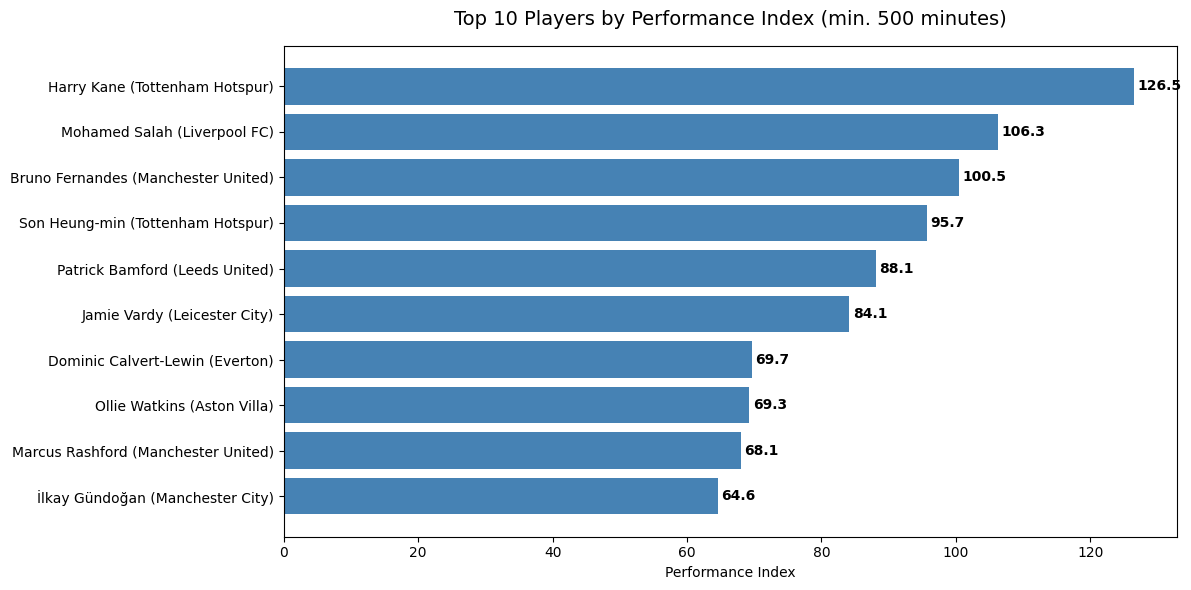

                 Name              Club Position  Goals  Assists  Mins  Performance_Index
           Harry Kane Tottenham Hotspur       FW     23       14  3082             126.51
        Mohamed Salah      Liverpool FC       FW     22        5  3078             106.32
      Bruno Fernandes Manchester United       MF     18       12  3099             100.46
        Son Heung-min Tottenham Hotspur       FW     17       10  3114              95.67
      Patrick Bamford      Leeds United       FW     17        7  3050              88.13
          Jamie Vardy    Leicester City       FW     15        9  2840              84.14
Dominic Calvert-Lewin           Everton       FW     16        0  2871              69.66
        Ollie Watkins       Aston Villa       FW     14        5  3328              69.28
      Marcus Rashford Manchester United       FW     11        9  2920              68.06
       İlkay Gündoğan   Manchester City       MF     13        2  2029              64.60


In [3]:
# Top 10 players by Performance Index (min 500 minutes)
top10 = players[players['Mins'] >= 500].nlargest(10, 'Performance_Index')

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top10['Name'] + ' (' + top10['Club'] + ')', 
               top10['Performance_Index'], 
               color='steelblue')

# Add values on bars
for bar, val in zip(bars, top10['Performance_Index']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}', va='center', fontweight='bold')

ax.set_title('Top 10 Players by Performance Index (min. 500 minutes)', 
             fontsize=14, pad=15)
ax.set_xlabel('Performance Index')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Print table
print(top10[['Name', 'Club', 'Position', 'Goals', 'Assists', 
             'Mins', 'Performance_Index']].to_string(index=False))

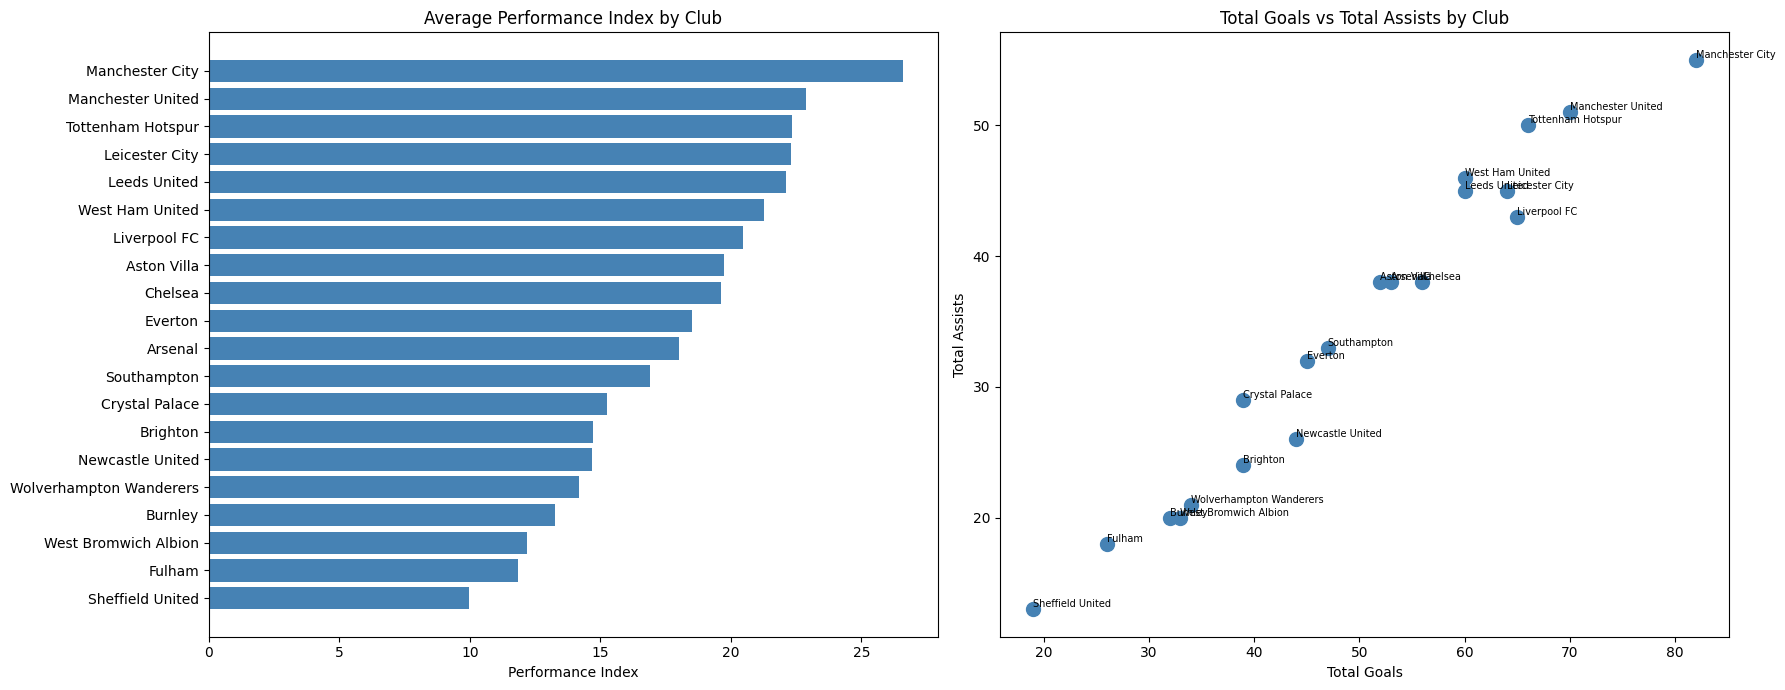

                   Club  avg_performance  total_goals  total_assists  avg_pass_accuracy
        Manchester City            26.61           82             55              87.40
      Manchester United            22.88           70             51              83.60
      Tottenham Hotspur            22.35           66             50              79.35
         Leicester City            22.31           64             45              79.65
           Leeds United            22.11           60             45              79.41
        West Ham United            21.27           60             46              75.87
           Liverpool FC            20.45           65             43              83.77
            Aston Villa            19.75           52             38              76.98
                Chelsea            19.61           56             38              84.27
                Everton            18.51           45             32              79.39
                Arsenal         

In [4]:
# Average performance index by club
club_stats = players.groupby('Club').agg(
    avg_performance=('Performance_Index', 'mean'),
    total_goals=('Goals', 'sum'),
    total_assists=('Assists', 'sum'),
    avg_pass_accuracy=('Perc_Passes_Completed', 'mean'),
    player_count=('Name', 'count')
).round(2).reset_index()

club_stats = club_stats.sort_values('avg_performance', ascending=False)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Chart 1: Average Performance Index by club
axes[0].barh(club_stats['Club'], club_stats['avg_performance'], color='steelblue')
axes[0].set_title('Average Performance Index by Club')
axes[0].set_xlabel('Performance Index')
axes[0].invert_yaxis()

# Chart 2: Total goals vs total assists
axes[1].scatter(club_stats['total_goals'], club_stats['total_assists'], 
                color='steelblue', s=100)
for _, row in club_stats.iterrows():
    axes[1].annotate(row['Club'], (row['total_goals'], row['total_assists']),
                    fontsize=7, ha='left', va='bottom')
axes[1].set_title('Total Goals vs Total Assists by Club')
axes[1].set_xlabel('Total Goals')
axes[1].set_ylabel('Total Assists')

plt.tight_layout()
plt.show()

print(club_stats[['Club', 'avg_performance', 'total_goals', 
                   'total_assists', 'avg_pass_accuracy']].to_string(index=False))

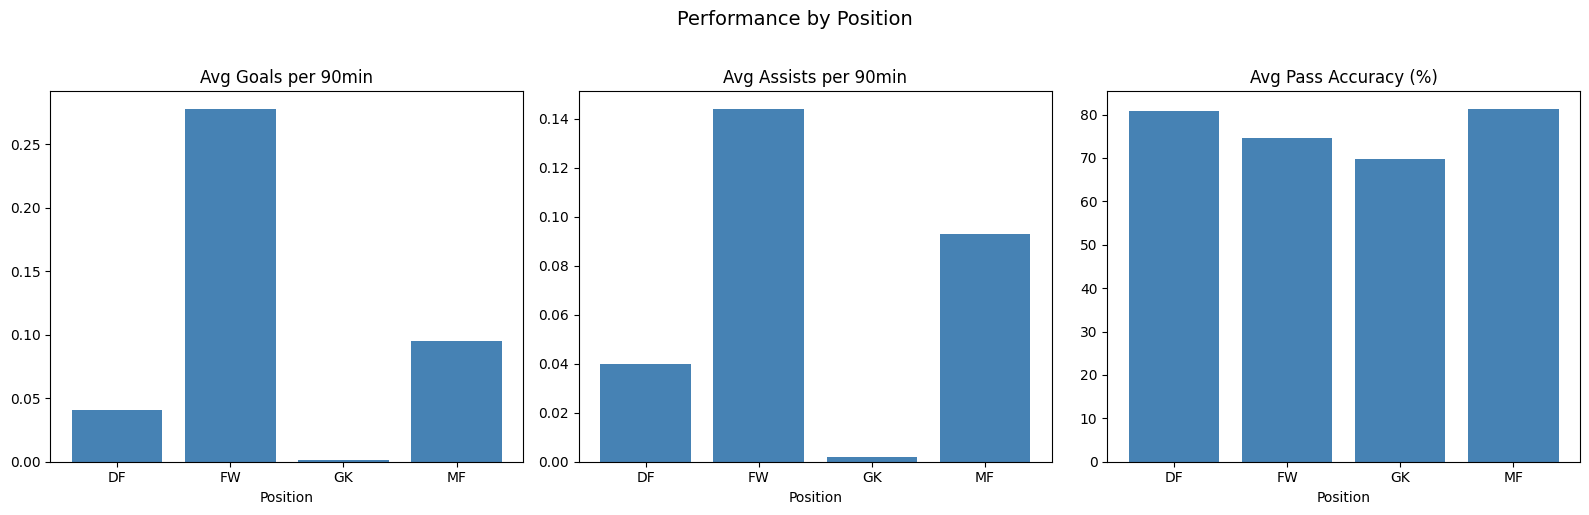

Position_Clean  avg_goals  avg_assists  avg_pass_accuracy  player_count
            DF      0.041        0.040             80.896           180
            FW      0.278        0.144             74.525           112
            GK      0.001        0.002             69.662            40
            MF      0.095        0.093             81.291           143


In [5]:
# Clean positions (some players have combined positions like MF,FW)
players['Position_Clean'] = players['Position'].str.split(',').str[0]

# Stats by position
position_stats = players.groupby('Position_Clean').agg(
    avg_goals=('Goals_per90', 'mean'),
    avg_assists=('Assists_per90', 'mean'),
    avg_pass_accuracy=('Perc_Passes_Completed', 'mean'),
    player_count=('Name', 'count')
).round(3).reset_index()

position_stats = position_stats[position_stats['player_count'] >= 10]

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['avg_goals', 'avg_assists', 'avg_pass_accuracy']
titles = ['Avg Goals per 90min', 'Avg Assists per 90min', 'Avg Pass Accuracy (%)']

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(position_stats['Position_Clean'], 
           position_stats[metric], color='steelblue')
    ax.set_title(title)
    ax.set_xlabel('Position')

plt.suptitle('Performance by Position', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(position_stats.to_string(index=False))

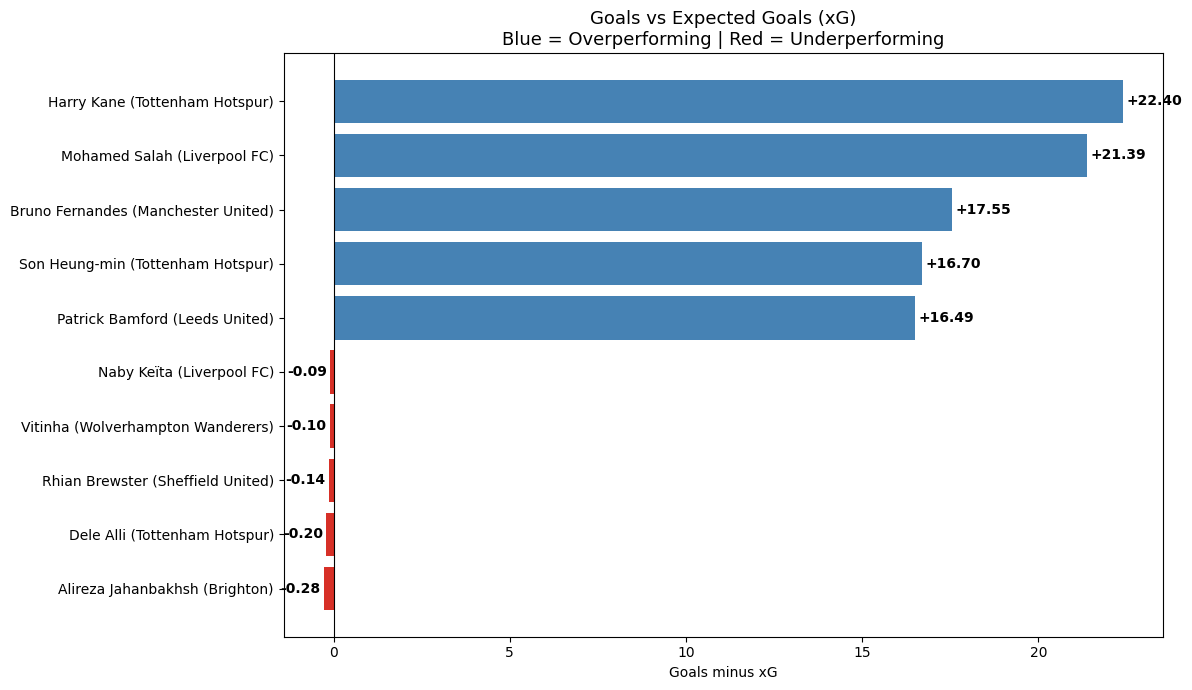


Top overperformers:
           Name              Club  Goals   xG  xG_diff
     Harry Kane Tottenham Hotspur     23 0.60    22.40
  Mohamed Salah      Liverpool FC     22 0.61    21.39
Bruno Fernandes Manchester United     18 0.45    17.55
  Son Heung-min Tottenham Hotspur     17 0.30    16.70
Patrick Bamford      Leeds United     17 0.51    16.49

Top underperformers:
               Name                    Club  Goals   xG  xG_diff
Alireza Jahanbakhsh                Brighton      0 0.28    -0.28
          Dele Alli       Tottenham Hotspur      0 0.20    -0.20
     Rhian Brewster        Sheffield United      0 0.14    -0.14
            Vitinha Wolverhampton Wanderers      0 0.10    -0.10
         Naby Keïta            Liverpool FC      0 0.09    -0.09


In [6]:
# Filter forwards and midfielders with min 500 minutes
attackers = players[
    (players['Position_Clean'].isin(['FW', 'MF'])) & 
    (players['Mins'] >= 500) &
    (players['xG'] > 0)
].copy()

# Calculate overperformance
attackers['xG_diff'] = (attackers['Goals'] - attackers['xG']).round(2)

# Top overperformers and underperformers
top_over = attackers.nlargest(5, 'xG_diff')
top_under = attackers.nsmallest(5, 'xG_diff')
combined = pd.concat([top_over, top_under]).sort_values('xG_diff', ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
colors = ['#d73027' if x < 0 else 'steelblue' for x in combined['xG_diff']]
bars = ax.barh(combined['Name'] + ' (' + combined['Club'] + ')', 
               combined['xG_diff'], color=colors)

ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('Goals vs Expected Goals (xG)\nBlue = Overperforming | Red = Underperforming', 
             fontsize=13)
ax.set_xlabel('Goals minus xG')

# Add values
for bar, val in zip(bars, combined['xG_diff']):
    ax.text(val + (0.1 if val >= 0 else -0.1), 
            bar.get_y() + bar.get_height()/2,
            f'{val:+.2f}', va='center', 
            ha='left' if val >= 0 else 'right',
            fontweight='bold')

plt.tight_layout()
plt.show()

print("\nTop overperformers:")
print(top_over[['Name', 'Club', 'Goals', 'xG', 'xG_diff']].to_string(index=False))
print("\nTop underperformers:")
print(top_under[['Name', 'Club', 'Goals', 'xG', 'xG_diff']].to_string(index=False))


In [7]:
# ── Project Summary ─────────────────────────────────────────────
# Dataset: English Premier League 2020/21 Season (475 players)
#
# Key findings:
#
# 1. TOP PERFORMERS
#    - Harry Kane ranked #1 by Performance Index (126.5)
#    - Mohamed Salah #2 (106.3), Bruno Fernandes #3 (100.5)
#
# 2. CLUB DOMINANCE
#    - Manchester City had highest avg Performance Index (26.5)
#    - Sheffield United lowest — relegated that season (confirmed by data)
#    - Strong correlation between total goals and total assists per club
#
# 3. POSITION ANALYSIS
#    - Forwards: most goals (0.278/90min) and assists (0.144/90min)
#    - Defenders & Midfielders: highest pass accuracy (~81%)
#    - Goalkeepers: near-zero attacking contribution (expected)
#
# 4. xG ANALYSIS (Goals vs Expected Goals)
#    - Kane overperformed xG by +22.40 goals — exceptional finisher
#    - Salah overperformed by +21.39
#    - Dele Alli underperformed (-0.20) — explains his poor season
#
# Tools: Python, pandas, matplotlib, seaborn
# ────────────────────────────────────────────────────────────────
print("Analysis complete.")

Analysis complete.
